# Exp16 v2 — Residual-stream patching at depth (IOI), fixed DE / HI

Supersedes the first Exp16 notebook. **Results go to a new folder (`exp16_v2_results/`) on purpose** — the old `exp16_results/` files were produced with templates and a floor design that this notebook changes, and must not be silently reloaded.

**Question.** For IOI, are residual-stream states *causally interchangeable* between EN and a target language at every depth, or does interchangeability break somewhere in the stack? (This is a computational-interchangeability test, not a representational-similarity test.)

**Method.** Patch the final-position residual at the end of layer `L` in a target-language forward pass with the matched EN donor activation. `compat(L) = (patched − ablated) / (clean − ablated)`, all scored on the target prompt with the target prompt's own IO / S name tokens.

## What changed from v1, and why

| # | v1 problem | v2 fix |
|---|---|---|
| 1 | DE templates ended in `an` (4) or `zu` (2); HI templates ended in six different verbs → floor failed at L=0 because the final-token residual differs across templates | **Every template within a language ends in one identical token**: EN `to`, FR `à`, DE `an`, HI `ने`. Verified by a tokenizer preflight that asserts it. |
| 2 | HI templates ended in a verb, but Hindi is SOV: the indirect object precedes the verb, so a name after the verb is unnatural (probable cause of baseline < 0.75) | HI templates end at the ergative marker `ने` so the IO name is the natural next token (`… A ने [B] को …`). |
| 3 | HI used EN names inside Hindi templates (code-switched) | **Two HI conditions** are run side by side: `hi_matched` (EN names, Exp14 convention, same name tokens on both sides) and `hi_native` (native Devanagari names; EN donor uses the paired EN transliteration). |
| 4 | Cross and floor used different name draws and different target prompts | Cross and floor now share the **identical target prompt** per pair (same names, same template); only the donor differs (EN template vs. next target-language template). Clean and ablated are computed once and reused. |
| 5 | Floor was only checked at 5 checkpoint layers; depth-of-split could fire on untrusted layers | Floor is checked at **every** L; `depth_of_split` is computed over floor-trusted layers only; untrusted layers are shaded in the plots. |
| 6 | compat exploded (−119, +26) when `clean − ablated` was near zero | Compat is `NaN` (and counted as untrusted) wherever `|clean − ablated| < DEN_MIN` logits. |
| 7 | Cached results could be silently reloaded after a template edit | Every cache file carries a spec version + hash of templates and names; a mismatch triggers a recompute. |

## How to read the curves (new, important)

- **At `L = n_layers − 1` compat is a tautology, not a test.** Patching the last layer's output at the final position reproduces the donor's output logits exactly, so cross compat there equals (donor logit-diff) / (target logit-diff) — a *confidence ratio*. A value above 1 (e.g. DE at 1.2–1.5 in v1) just means the EN prompt is more confident than the target prompt. To make this visible, a second, **donor-normalized** curve is stored and plotted (dotted grey): `(patched − ablated) / (donor_clean − ablated)`.
- **Floor at the last layer is ≈1 up to sampling noise**: it equals mean(donor logit-diff) / mean(target logit-diff), and templates are balanced across donor and target roles, so it carries almost no information about the method there. Floor deviations at *middle* layers are the informative ones.
- **`hi_native` late layers are expected to fall for a trivial reason**: the late residual encodes which *output token* comes next, and EN `B` and HI `B` are different tokens. Compare `hi_native` against `hi_matched` (same output tokens) before reading any late-layer fall as language-specific computation.

**Controls (none optional).** Self-test (identity patch, compat ≈ 1) → floor control at every L → baseline accuracy ≥ 0.75 on the target language per scale.

Run top to bottom through the **PREFLIGHT** cell and **RUN 1** (2B). Inspect, check the decision rules, then trigger **RUN 2**.

## Environment

In [1]:
import os
# CUDA_VISIBLE_DEVICES must be set BEFORE importing torch (project convention: GPU 2).
os.environ["CUDA_VISIBLE_DEVICES"] = "1"

import gc, hashlib, json, random, time, warnings
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from transformers import AutoModelForCausalLM, AutoTokenizer

warnings.filterwarnings("ignore", category=UserWarning)
torch.set_grad_enabled(False)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.bfloat16

print(f"torch={torch.__version__}  device={DEVICE}  dtype={DTYPE}")
if torch.cuda.is_available():
    gib = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"gpu: {torch.cuda.get_device_name(0)}  mem={gib:.1f} GiB")

/home/anwoy/miniconda3/envs/ke/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch=2.11.0+cu130  device=cuda  dtype=torch.bfloat16
gpu: NVIDIA H200 NVL  mem=139.8 GiB


In [2]:
MODEL_SPECS = {
    "2b_base": "google/gemma-2-2b",        # no local folder on this machine; HF hub id
    "9b_base": "/home/models/gemma-2-9b",
    "9b_it":   "/home/models/gemma-2-9b-it",
    "27b_it":  "/home/models/gemma-2-27b-it",
}

SEEDS        = [0, 7, 13]                  # Exp13 / 14 convention
N_PROMPTS    = 120
TARGET_LANGS = ["fr", "de", "hi_matched", "hi_native"]

SPEC_VERSION = "v2"
RESULTS_DIR  = Path("exp16_v2_results")    # NEW dir: v1 files used different templates / floor design
RESULTS_DIR.mkdir(exist_ok=True)
EXP14_DIR    = Path("exp14_results")       # optional, provenance only

BASELINE_MIN = 0.75     # target-language IOI accuracy gate
FLOOR_LO, FLOOR_HI = 0.9, 1.1
DEN_MIN      = 1.0      # |clean - ablated| (logits) below this -> compat = NaN (untrusted)
MIN_NAMES    = 10       # fewer usable single-token names than this -> language unavailable

print(f"results dir: {RESULTS_DIR.resolve()}  (spec {SPEC_VERSION})")

results dir: /home/anwoy/exp16_v2_results  (spec v2)


## Names and templates

**Templates (6 per language, same event structure: subject gives an object to the indirect object).** Within a language *every template ends in the same token*, so the final-position residual at low `L` is comparable across templates and the floor control is a fair test:

- EN `to` · FR `à` · DE `an` · HI `ने`

**Hindi is SOV.** The indirect object comes *before* the verb (`… A ने B को पैसे दिए`), so the prompt stops at `ने` and the IO name is the next token. The object being given is therefore not stated in the HI prompt (it follows the IO in Hindi); the EN/FR/DE templates state it. This is a deliberate structural difference, not an oversight.

**Name conditions.**
- `fr`, `de`, `hi_matched`: EN names in the target template (Exp14 matched-prompt convention; the correct next token is the same token on donor and target side).
- `hi_native`: native Devanagari names in the HI template; the EN donor uses the *paired* EN transliteration (name `i` ↔ name `i`). Only names where **both** sides are single-token are kept.

In [3]:
EN_NAMES = [
    "John", "Mary", "Michael", "Jennifer", "David",
    "Linda", "James", "Patricia", "Robert", "Susan",
    "Thomas", "Karen", "Daniel", "Sarah", "Mark",
    "Nancy", "Paul", "Laura", "George", "Rachel",
]

# (EN transliteration, Devanagari). A pair is kept only if BOTH are single-token (leading-space form).
HI_NATIVE_PAIRS = [
    ("Arjun", "अर्जुन"), ("Priya", "प्रिया"), ("Vikas", "विकास"), ("Sita", "सीता"),
    ("Ram", "राम"), ("Krishna", "कृष्ण"), ("Radha", "राधा"), ("Ajay", "अजय"),
    ("Anita", "अनिता"), ("Deepak", "दीपक"), ("Meera", "मीरा"), ("Ravi", "रवि"),
    ("Sunil", "सुनील"), ("Geeta", "गीता"), ("Amit", "अमित"), ("Reena", "रीना"),
    ("Suresh", "सुरेश"), ("Kavita", "कविता"), ("Manoj", "मनोज"), ("Sheila", "शीला"),
    ("Nikhil", "निखिल"), ("Neelam", "नीलम"), ("Sanjay", "संजय"), ("Jyoti", "ज्योति"),
    ("Vishal", "विशाल"), ("Rekha", "रेखा"), ("Ashok", "अशोक"), ("Pooja", "पूजा"),
    ("Rajesh", "राजेश"), ("Anushka", "अनुष्का"),
]

In [4]:
EN_TEMPLATES = [   # all end in "to"
    "When {A} and {B} went to the store, {A} gave a drink to",
    "After {A} and {B} finished their work, {A} handed the keys to",
    "At the park, {A} and {B} were playing, then {A} tossed the ball to",
    "In the office, {A} and {B} were talking, and {A} passed the report to",
    "At the market, {A} and {B} were shopping, so {A} gave the money to",
    "During the meeting, {A} and {B} were sitting, and {A} slid the paper to",
]

FR_TEMPLATES = [   # all end in "à"
    "Quand {A} et {B} sont allés au magasin, {A} a donné une boisson à",
    "Après que {A} et {B} ont fini leur travail, {A} a remis les clés à",
    "Au parc, {A} et {B} jouaient, puis {A} a lancé le ballon à",
    "Au bureau, {A} et {B} discutaient, et {A} a passé le rapport à",
    "Au marché, {A} et {B} faisaient leurs courses, donc {A} a donné l'argent à",
    "Pendant la réunion, {A} et {B} étaient assis, et {A} a glissé le papier à",
]

DE_TEMPLATES = [   # all end in "an"  (v1 mixed "an" and "zu")
    "Als {A} und {B} zum Laden gingen, gab {A} ein Getränk an",
    "Nachdem {A} und {B} ihre Arbeit beendet hatten, reichte {A} die Schlüssel an",
    "Im Park spielten {A} und {B}, dann gab {A} den Ball an",
    "Im Büro sprachen {A} und {B}, und {A} gab den Bericht an",
    "Auf dem Markt kauften {A} und {B} ein, also gab {A} das Geld an",
    "Während des Treffens saßen {A} und {B}, und {A} gab das Papier an",
]

HI_TEMPLATES = [   # all end in "ने"; the IO name is the natural next token (SOV: IO precedes the verb)
    "जब {A} और {B} दुकान गए, तो {A} ने",
    "{A} और {B} ने काम खत्म किया, फिर {A} ने",
    "बाग में {A} और {B} खेल रहे थे, तब {A} ने",
    "दफ्तर में {A} और {B} बात कर रहे थे, और {A} ने",
    "बाजार में {A} और {B} खरीदारी कर रहे थे, इसलिए {A} ने",
    "मीटिंग के दौरान {A} और {B} बैठे थे, और {A} ने",
]

TEMPLATES = {"en": EN_TEMPLATES, "fr": FR_TEMPLATES, "de": DE_TEMPLATES, "hi": HI_TEMPLATES}
assert all(len(v) == 6 for v in TEMPLATES.values()), "each language needs exactly 6 templates"

LANG_CFG = {
    "fr":         {"tpl": "fr", "names": "en",        "desc": "FR templates, EN names (Exp14 matched)"},
    "de":         {"tpl": "de", "names": "en",        "desc": "DE templates, EN names (Exp14 matched)"},
    "hi_matched": {"tpl": "hi", "names": "en",        "desc": "HI templates, EN names (Exp14 matched)"},
    "hi_native":  {"tpl": "hi", "names": "hi_native", "desc": "HI templates, native HI names; EN donor uses paired EN transliteration"},
}

In [5]:
class LangUnavailable(Exception):
    """Raised when a language/condition cannot be built cleanly (e.g. too few single-token names)."""


def single_token_id(tok, text):
    """Token id of ' text' (leading-space, mid-sentence form) if it is exactly one token, else None."""
    ids = tok.encode(" " + text, add_special_tokens=False)
    return ids[0] if len(ids) == 1 else None


def get_name_inventory(tok, lang):
    """Returns (target_names, donor_names): index-aligned lists of (name, token_id)."""
    mode = LANG_CFG[lang]["names"]
    if mode == "en":
        inv = [(n, single_token_id(tok, n)) for n in EN_NAMES]
        inv = [(n, i) for n, i in inv if i is not None]
        if len(inv) < MIN_NAMES:
            raise LangUnavailable(f"{lang}: only {len(inv)} single-token EN names (< {MIN_NAMES})")
        return inv, inv
    tgt, don = [], []
    for en, hi in HI_NATIVE_PAIRS:
        e_id, h_id = single_token_id(tok, en), single_token_id(tok, hi)
        if e_id is not None and h_id is not None:
            tgt.append((hi, h_id))
            don.append((en, e_id))
    if len(tgt) < MIN_NAMES:
        raise LangUnavailable(
            f"{lang}: only {len(tgt)} name pairs have BOTH sides single-token (< {MIN_NAMES}); "
            f"condition disabled. Not substituting multi-token names.")
    return tgt, don


def spec_hash(lang):
    cfg = LANG_CFG[lang]
    # hash only what this condition actually uses, so editing HI names never invalidates FR/DE caches
    names_used = EN_NAMES if cfg["names"] == "en" else HI_NATIVE_PAIRS
    blob = json.dumps({
        "tgt_tpl": TEMPLATES[cfg["tpl"]], "en_tpl": TEMPLATES["en"],
        "names_mode": cfg["names"], "names": names_used,
        "scheme": "v2-shared-target-cyclic-floor",
    }, ensure_ascii=False, sort_keys=True)
    return hashlib.md5(blob.encode("utf-8")).hexdigest()[:12]

In [6]:
def build_pairs(tok, lang, n_prompts, seed):
    """Per pair i (template t = i % 6):
         target_prompt : target-language template t, target names             (scored here)
         donor_cross   : EN template t, donor names (same slot identities)     (cross donor)
         donor_floor   : target-language template (t+1) % 6, SAME target names (floor donor)
       Cross and floor therefore share the identical target prompt; only the donor differs.
       Position i is the matched pair across all lists. No shuffling, no pooling."""
    cfg = LANG_CFG[lang]
    tgt_tpl, en_tpl = TEMPLATES[cfg["tpl"]], TEMPLATES["en"]
    tgt_names, don_names = get_name_inventory(tok, lang)
    rng = random.Random(seed)
    n = len(tgt_names)
    pairs = []
    for i in range(n_prompts):
        a = rng.randrange(n)
        b = rng.choice([j for j in range(n) if j != a])
        t = i % len(tgt_tpl)
        a_t, a_tid = tgt_names[a]
        b_t, b_tid = tgt_names[b]
        a_d, a_did = don_names[a]
        b_d, b_did = don_names[b]
        pairs.append({
            "target_prompt": tgt_tpl[t].format(A=a_t, B=b_t),
            "donor_cross":   en_tpl[t].format(A=a_d, B=b_d),
            "donor_floor":   tgt_tpl[(t + 1) % len(tgt_tpl)].format(A=a_t, B=b_t),
            "io_id": b_tid, "s_id": a_tid,           # target-side readout tokens
            "d_io_id": b_did, "d_s_id": a_did,       # donor-side tokens (cross donor)
            "io_name": b_t, "d_io_name": b_d,
            "template_idx": t,
        })
    return pairs

## Tokenizer preflight (no model needed)

Asserts the fix for the v1 floor failure: **within each language, every template ends in the same token.** Also checks that appending ` <name>` to a prompt adds exactly one token and leaves the prompt tokens untouched (otherwise name-token scoring would be reading the wrong position), and reports how many native HI name pairs are usable.

In [7]:
def check_final_tokens(tok):
    """Every template in a language must end in an identical token id."""
    report = {}
    for lg, tpls in TEMPLATES.items():
        last_ids = set()
        for t in tpls:
            ids = tok.encode(t.format(A="Mary", B="John"), add_special_tokens=False)
            last_ids.add(ids[-1])
        piece = tok.decode([sorted(last_ids)[0]])
        report[lg] = (len(last_ids) == 1, sorted(last_ids), piece)
    return report


def check_prefix_consistency(tok, lang, n=12):
    """tok(prompt + ' ' + name) must equal tok(prompt) + [name_id] for both target and donor prompts."""
    pairs = build_pairs(tok, lang, n, seed=0)
    bad = 0
    for p in pairs:
        for prompt, name, nid in ((p["target_prompt"], p["io_name"], p["io_id"]),
                                  (p["donor_cross"], p["d_io_name"], p["d_io_id"])):
            base = tok.encode(prompt, add_special_tokens=False)
            full = tok.encode(prompt + " " + name, add_special_tokens=False)
            if not (full[:len(base)] == base and len(full) == len(base) + 1 and full[-1] == nid):
                bad += 1
    return bad, 2 * len(pairs)


def preflight(tok):
    print("=== final-token constancy (must be one id per language) ===")
    rep = check_final_tokens(tok)
    ok_all = True
    for lg, (ok, ids, piece) in rep.items():
        print(f"  {lg:>2s}: {'OK ' if ok else 'FAIL'}  ids={ids}  last token={piece!r}")
        ok_all = ok_all and ok
    print("=== name inventories ===")
    avail = {}
    for lg in TARGET_LANGS:
        try:
            tgt, don = get_name_inventory(tok, lg)
            avail[lg] = len(tgt)
            print(f"  {lg:<10s}: {len(tgt):>2d} usable names")
        except LangUnavailable as e:
            avail[lg] = 0
            print(f"  {lg:<10s}: UNAVAILABLE -> {e}")
    print("=== prefix consistency (name token scoring position) ===")
    pref_ok = True
    for lg in TARGET_LANGS:
        if avail[lg] == 0:
            continue
        bad, tot = check_prefix_consistency(tok, lg)
        print(f"  {lg:<10s}: {tot - bad}/{tot} consistent")
        pref_ok = pref_ok and bad == 0
    return ok_all, pref_ok, avail

In [8]:
# PREFLIGHT — tokenizer only (all Gemma-2 sizes share the tokenizer). Run before RUN 1.
_tok = AutoTokenizer.from_pretrained(MODEL_SPECS["2b_base"])
_final_ok, _prefix_ok, _avail = preflight(_tok)
assert _final_ok, "A language has templates ending in different tokens -> floor control would fail again. Fix templates."
assert _prefix_ok, "Name-token scoring position is inconsistent for some language. Paste this output back before running."
print()
print("PREFLIGHT PASSED. Languages that will run:", [k for k, v in _avail.items() if v])
del _tok

=== final-token constancy (must be one id per language) ===
  en: OK   ids=[577]  last token=' to'
  fr: OK   ids=[1305]  last token=' à'
  de: OK   ids=[671]  last token=' an'
  hi: OK   ids=[24220]  last token=' ने'
=== name inventories ===
  fr        : 20 usable names
  de        : 20 usable names
  hi_matched: 20 usable names
  hi_native : UNAVAILABLE -> hi_native: only 1 name pairs have BOTH sides single-token (< 10); condition disabled. Not substituting multi-token names.
=== prefix consistency (name token scoring position) ===
  fr        : 24/24 consistent
  de        : 24/24 consistent
  hi_matched: 24/24 consistent

PREFLIGHT PASSED. Languages that will run: ['fr', 'de', 'hi_matched']


In [9]:
_tok = AutoTokenizer.from_pretrained(MODEL_SPECS["2b_base"])
def pieces(s): return _tok.convert_ids_to_tokens(_tok.encode(" " + s, add_special_tokens=False))
n_hi = n_en = 0
for en, hi in HI_NATIVE_PAIRS:
    pe, ph = pieces(en), pieces(hi)
    n_hi += len(ph) == 1; n_en += len(pe) == 1
    print(f"{en:<8s} EN {len(pe)} {pe}   |   {hi} HI {len(ph)} {ph}")
print(f"single-token: HI side {n_hi}/{len(HI_NATIVE_PAIRS)}, EN side {n_en}/{len(HI_NATIVE_PAIRS)}")

Arjun    EN 1 ['▁Arjun']   |   अर्जुन HI 3 ['▁अर्', 'ज', 'ुन']
Priya    EN 1 ['▁Priya']   |   प्रिया HI 2 ['▁प्र', 'िया']
Vikas    EN 2 ['▁Vik', 'as']   |   विकास HI 1 ['▁विकास']
Sita     EN 1 ['▁Sita']   |   सीता HI 2 ['▁सी', 'ता']
Ram      EN 1 ['▁Ram']   |   राम HI 1 ['▁राम']
Krishna  EN 1 ['▁Krishna']   |   कृष्ण HI 2 ['▁कृ', 'ष्ण']
Radha    EN 1 ['▁Radha']   |   राधा HI 2 ['▁रा', 'धा']
Ajay     EN 1 ['▁Ajay']   |   अजय HI 2 ['▁अ', 'जय']
Anita    EN 1 ['▁Anita']   |   अनिता HI 2 ['▁अन', 'िता']
Deepak   EN 1 ['▁Deepak']   |   दीपक HI 3 ['▁दी', 'प', 'क']
Meera    EN 2 ['▁Me', 'era']   |   मीरा HI 2 ['▁मी', 'रा']
Ravi     EN 1 ['▁Ravi']   |   रवि HI 2 ['▁र', 'वि']
Sunil    EN 1 ['▁Sunil']   |   सुनील HI 3 ['▁सु', 'नी', 'ल']
Geeta    EN 2 ['▁Gee', 'ta']   |   गीता HI 3 ['▁ग', 'ी', 'ता']
Amit     EN 1 ['▁Amit']   |   अमित HI 2 ['▁अ', 'मित']
Reena    EN 2 ['▁Re', 'ena']   |   रीना HI 3 ['▁र', 'ी', 'ना']
Suresh   EN 1 ['▁Suresh']   |   सुरेश HI 2 ['▁सुर', 'ेश']
Kavita   EN 2 ['▁Kav', 'ita

## Model loader and hooks

In [9]:
def load_model(model_key):
    path = MODEL_SPECS[model_key]
    print(f"[load] {model_key}  <-  {path}")
    t0 = time.time()
    tok = AutoTokenizer.from_pretrained(path)
    model = AutoModelForCausalLM.from_pretrained(path, dtype=DTYPE, device_map=DEVICE).eval()
    print(f"[load] ready in {time.time() - t0:.1f}s  n_layers={model.config.num_hidden_layers}  d_model={model.config.hidden_size}")
    return model, tok


def free_model(model):
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def load_exp14_cache(model_key):
    """Provenance only: this notebook builds its own prompts."""
    path = EXP14_DIR / f"{model_key}.json"
    if not path.exists():
        print(f"[exp14 cache] {path} not found (fine: prompts are built fresh)")
        return None
    try:
        with open(path) as f:
            data = json.load(f)
        print(f"[exp14 cache] found {path}")
        return data
    except Exception as e:
        print(f"[exp14 cache] unreadable ({e!r}); ignoring")
        return None

In [10]:
def _layer_module(model, L):
    return model.model.layers[L]


def capture_last_token_hook(storage):
    def hook(module, inp, out):
        hs = out[0] if isinstance(out, tuple) else out
        storage["act"] = hs[:, -1, :].detach().clone()
    return hook


def patch_last_token_hook(donor_act):
    """Replace final-position hidden state with donor_act. CLONE first, never in place
    (Gemma-2 reuses tensors across layers; in-place writes corrupt the forward pass)."""
    def hook(module, inp, out):
        if isinstance(out, tuple):
            new_hs = out[0].clone()
            new_hs[:, -1, :] = donor_act.to(new_hs.dtype)
            return (new_hs,) + out[1:]
        new_hs = out.clone()
        new_hs[:, -1, :] = donor_act.to(new_hs.dtype)
        return new_hs
    return hook


def zero_last_token_hook():
    def hook(module, inp, out):
        if isinstance(out, tuple):
            new_hs = out[0].clone()
            new_hs[:, -1, :] = 0.0
            return (new_hs,) + out[1:]
        new_hs = out.clone()
        new_hs[:, -1, :] = 0.0
        return new_hs
    return hook


def tokenize(tok, prompt):
    return tok(prompt, return_tensors="pt").input_ids.to(DEVICE)


def logit_diff(logits, io_id, s_id):
    return (logits[io_id] - logits[s_id]).item()


@torch.no_grad()
def forward_logits_last(model, tok, prompt):
    return model(input_ids=tokenize(tok, prompt), use_cache=False).logits[0, -1, :]


@torch.no_grad()
def capture_all_layers(model, tok, prompt, n_layers):
    """One forward pass, capture hooks at every layer boundary.
    Returns ({L: hidden vector [d_model]}, final-position logits)."""
    ids = tokenize(tok, prompt)
    storages = [dict() for _ in range(n_layers)]
    handles = [_layer_module(model, L).register_forward_hook(capture_last_token_hook(storages[L]))
               for L in range(n_layers)]
    try:
        out = model(input_ids=ids, use_cache=False)
    finally:
        for h in handles:
            h.remove()
    return {L: storages[L]["act"][0] for L in range(n_layers)}, out.logits[0, -1, :]


@torch.no_grad()
def forward_with_hook(model, tok, prompt, layer_L, hook):
    ids = tokenize(tok, prompt)
    handle = _layer_module(model, layer_L).register_forward_hook(hook)
    try:
        out = model(input_ids=ids, use_cache=False)
    finally:
        handle.remove()
    return out.logits[0, -1, :]

## Self-test — identity patching must give compat ≈ 1.0

Patch each EN prompt with its **own** captured residual at the first, middle and last layer (ratio of means over several prompts). Compat must be `1.0 ± 0.05` everywhere or the hook is broken — **stop and fix before running anything else.**

In [11]:
def self_test(model, tok, n_test=6, test_layers=None, tol=0.05):
    n_layers = model.config.num_hidden_layers
    test_layers = test_layers or [0, n_layers // 2, n_layers - 1]
    pairs = build_pairs(tok, "fr", n_test, seed=0)       # use the EN donor side only

    clean, abl = [], {L: [] for L in test_layers}
    pat = {L: [] for L in test_layers}
    for p in pairs:
        prompt, io, s = p["donor_cross"], p["d_io_id"], p["d_s_id"]
        acts, logits = capture_all_layers(model, tok, prompt, n_layers)
        clean.append(logit_diff(logits, io, s))
        for L in test_layers:
            pat[L].append(logit_diff(forward_with_hook(model, tok, prompt, L, patch_last_token_hook(acts[L])), io, s))
            abl[L].append(logit_diff(forward_with_hook(model, tok, prompt, L, zero_last_token_hook()), io, s))

    clean_m = float(np.mean(clean))
    print(f"[self-test] {n_test} EN prompts, mean clean logit-diff = {clean_m:+.4f}")
    all_ok, compats = True, {}
    for L in test_layers:
        a, pt = float(np.mean(abl[L])), float(np.mean(pat[L]))
        den = clean_m - a
        compat = (pt - a) / den if abs(den) >= 1e-6 else float("nan")
        ok = bool(abs(compat - 1.0) < tol)
        print(f"  L={L:>3d}  patched={pt:+.4f}  ablated={a:+.4f}  compat={compat:+.4f}  ok={ok}")
        compats[L] = compat
        all_ok = all_ok and ok
    print(f"[self-test] all_ok = {all_ok}")
    return all_ok, compats

## Per-(model, language, seed) sweep

Per pair: capture the EN donor and the floor donor (all layers, one pass each), one clean target pass, then for every `L` one ablated pass and two patched passes (cross, floor) on the **same** target prompt. Each prompt has its own donor activation; nothing is pooled.

In [12]:
def result_path(model_key, lang, seed):
    return RESULTS_DIR / f"{model_key}_{lang}_s{seed}.json"


def _compat(patched, ablated, ref_clean_mean):
    """Ratio of means. NaN where |ref_clean - ablated| < DEN_MIN (denominator too small to trust)."""
    abl_m = ablated.mean(axis=0)
    num = patched.mean(axis=0) - abl_m
    den = ref_clean_mean - abl_m
    out = np.full(num.shape, np.nan)
    ok = np.abs(den) >= DEN_MIN
    out[ok] = num[ok] / den[ok]
    return out.tolist()


@torch.no_grad()
def run_one(model, tok, model_key, lang, seed, n_prompts=N_PROMPTS, verbose=True):
    cache = result_path(model_key, lang, seed)
    h = spec_hash(lang)
    if cache.exists():
        with open(cache) as f:
            res = json.load(f)
        if res.get("spec_version") == SPEC_VERSION and res.get("spec_hash") == h and res.get("n_prompts") == n_prompts:
            if verbose:
                print(f"[run_one] cache hit {cache.name}")
            return res
        print(f"[run_one] STALE cache {cache.name} (spec/hash/n_prompts mismatch) -> recomputing")

    n_layers = model.config.num_hidden_layers
    pairs = build_pairs(tok, lang, n_prompts, seed)          # may raise LangUnavailable

    # quick baseline pass first so the gate is visible early in the log
    base_ok = [logit_diff(forward_logits_last(model, tok, p["target_prompt"]), p["io_id"], p["s_id"]) > 0 for p in pairs]
    print(f"[baseline] {model_key} {lang} s{seed}: target acc = {np.mean(base_ok):.3f}  (gate {BASELINE_MIN})")

    clean = np.zeros(n_prompts)
    donor_clean_cross = np.zeros(n_prompts)
    donor_clean_floor = np.zeros(n_prompts)
    ablated = np.zeros((n_prompts, n_layers))
    cross_patched = np.zeros((n_prompts, n_layers))
    floor_patched = np.zeros((n_prompts, n_layers))

    t0 = time.time()
    for i, p in enumerate(pairs):
        acts_c, logits_c = capture_all_layers(model, tok, p["donor_cross"], n_layers)
        acts_f, logits_f = capture_all_layers(model, tok, p["donor_floor"], n_layers)
        donor_clean_cross[i] = logit_diff(logits_c, p["d_io_id"], p["d_s_id"])
        donor_clean_floor[i] = logit_diff(logits_f, p["io_id"], p["s_id"])
        clean[i] = logit_diff(forward_logits_last(model, tok, p["target_prompt"]), p["io_id"], p["s_id"])
        for L in range(n_layers):
            ablated[i, L] = logit_diff(forward_with_hook(model, tok, p["target_prompt"], L, zero_last_token_hook()), p["io_id"], p["s_id"])
            cross_patched[i, L] = logit_diff(forward_with_hook(model, tok, p["target_prompt"], L, patch_last_token_hook(acts_c[L])), p["io_id"], p["s_id"])
            floor_patched[i, L] = logit_diff(forward_with_hook(model, tok, p["target_prompt"], L, patch_last_token_hook(acts_f[L])), p["io_id"], p["s_id"])
        if verbose and (i + 1) % 20 == 0:
            rate = (i + 1) / (time.time() - t0 + 1e-6)
            print(f"[{model_key} {lang} s{seed}] {i+1}/{n_prompts}  {rate:.2f} prompts/s  eta={(n_prompts-i-1)/max(rate,1e-6):.0f}s")

    tmpl = np.array([p["template_idx"] for p in pairs])
    clean_by_template = [float(clean[tmpl == t].mean()) if (tmpl == t).any() else float("nan") for t in range(6)]
    print(f"[diag] clean logit-diff by template (target): " + "  ".join(f"{v:+.2f}" for v in clean_by_template))

    res = {
        "spec_version": SPEC_VERSION, "spec_hash": h,
        "model_key": model_key, "lang": lang, "seed": seed,
        "condition": LANG_CFG[lang]["desc"],
        "n_prompts": n_prompts, "n_layers": n_layers, "den_min": DEN_MIN,
        "baseline_target": float(np.mean(clean > 0)),
        "baseline_donor":  float(np.mean(donor_clean_cross > 0)),
        "cross_compat":          _compat(cross_patched, ablated, clean.mean()),
        "floor_compat":          _compat(floor_patched, ablated, clean.mean()),
        "cross_compat_donornorm": _compat(cross_patched, ablated, donor_clean_cross.mean()),
        "floor_compat_donornorm": _compat(floor_patched, ablated, donor_clean_floor.mean()),
        "clean_mean": float(clean.mean()),
        "donor_clean_cross_mean": float(donor_clean_cross.mean()),
        "donor_clean_floor_mean": float(donor_clean_floor.mean()),
        "clean_by_template": clean_by_template,
        "ablated_mean": ablated.mean(axis=0).tolist(),
        "cross_patched_mean": cross_patched.mean(axis=0).tolist(),
        "floor_patched_mean": floor_patched.mean(axis=0).tolist(),
    }
    with open(cache, "w") as f:
        json.dump(res, f, indent=2)
    print(f"[run_one] wrote {cache.name}")
    return res

## Summary table and plots (mean ± std across seeds)

In [13]:
def load_seed_results(model_key, lang):
    out = []
    for s in SEEDS:
        p = result_path(model_key, lang, s)
        if p.exists():
            with open(p) as f:
                r = json.load(f)
            if r.get("spec_version") == SPEC_VERSION:
                out.append(r)
    return out


def aggregate_seeds(model_key, lang):
    rs = load_seed_results(model_key, lang)
    if not rs:
        return None
    arr = lambda k: np.array([r[k] for r in rs], dtype=float)
    cross, floor = arr("cross_compat"), arr("floor_compat")
    cross_dn = arr("cross_compat_donornorm")
    return {
        "n_layers": rs[0]["n_layers"], "n_seeds": len(rs),
        "cross_mean": cross.mean(axis=0), "cross_std": cross.std(axis=0),
        "floor_mean": floor.mean(axis=0), "floor_std": floor.std(axis=0),
        "cross_dn_mean": cross_dn.mean(axis=0),
        "baseline_target": float(np.mean([r["baseline_target"] for r in rs])),
        "baseline_donor":  float(np.mean([r["baseline_donor"] for r in rs])),
        "clean_by_template": np.nanmean(arr("clean_by_template"), axis=0),
    }


def _ranges(idx):
    idx = sorted(idx)
    if not idx:
        return "none"
    out, start, prev = [], idx[0], idx[0]
    for x in idx[1:]:
        if x == prev + 1:
            prev = x
            continue
        out.append((start, prev)); start = prev = x
    out.append((start, prev))
    return ",".join(f"{a}" if a == b else f"{a}-{b}" for a, b in out)


def summary_row(model_key, lang):
    agg = aggregate_seeds(model_key, lang)
    if agg is None:
        return None
    n = agg["n_layers"]
    cross, floor = agg["cross_mean"], agg["floor_mean"]
    floor_ok = (floor >= FLOOR_LO) & (floor <= FLOOR_HI)          # NaN -> False (untrusted)
    cps = sorted({0, n // 4, n // 2, 3 * n // 4, n - 1})
    split = np.where(floor_ok & (cross < 0.5))[0]
    baseline_ok = agg["baseline_target"] >= BASELINE_MIN
    if not baseline_ok:
        verdict = "UNTRUSTED (baseline)"
    elif floor_ok.all():
        verdict = "TRUSTED"
    else:
        verdict = f"PARTIAL ({int(floor_ok.sum())}/{n} layers floor-ok)"
    return {
        "model": model_key, "lang": lang, "n_layers": n, "n_seeds": agg["n_seeds"],
        "baseline_target": agg["baseline_target"], "baseline_donor": agg["baseline_donor"],
        "verdict": verdict, "n_floor_ok": int(floor_ok.sum()),
        "floor_bad_ranges": _ranges(np.where(~floor_ok)[0].tolist()),
        "depth_split_trusted": int(split[0]) if len(split) else None,
        "cps": cps, "floor_ok": floor_ok,
        "cross_at": {L: (float(cross[L]), float(agg["cross_std"][L])) for L in cps},
        "floor_at": {L: (float(floor[L]), float(agg["floor_std"][L])) for L in cps},
        "cross_dn_at": {L: float(agg["cross_dn_mean"][L]) for L in cps},
        "clean_by_template": agg["clean_by_template"],
    }


def print_summary_table(model_keys=None, langs=None):
    model_keys = model_keys or list(MODEL_SPECS)
    langs = langs or TARGET_LANGS
    shown = False
    for mk in model_keys:
        for lg in langs:
            r = summary_row(mk, lg)
            if r is None:
                continue
            shown = True
            ds = r["depth_split_trusted"] if r["depth_split_trusted"] is not None else "none (never < 0.5 at a floor-trusted L)"
            print()
            print(f"{mk} / {lg}  [{r['verdict']}]  n_layers={r['n_layers']}  seeds={r['n_seeds']}  "
                  f"baseline: target={r['baseline_target']:.2f} donor(EN)={r['baseline_donor']:.2f}")
            print(f"  depth_of_split (floor-trusted layers only): {ds}")
            print(f"  L                    : " + "  ".join(f"{L:>13d}" for L in r["cps"]))
            print(f"  cross compat (±std)  : " + "  ".join(f"{r['cross_at'][L][0]:+6.3f}±{r['cross_at'][L][1]:.2f}{' ' if r['floor_ok'][L] else '!'}" for L in r["cps"]))
            print(f"  floor compat (±std)  : " + "  ".join(f"{r['floor_at'][L][0]:+6.3f}±{r['floor_at'][L][1]:.2f}{' ' if r['floor_ok'][L] else '!'}" for L in r["cps"]))
            print(f"  cross, donor-normed  : " + "  ".join(f"{r['cross_dn_at'][L]:+13.3f}" for L in r["cps"]))
            print(f"  ('!' = floor outside [{FLOOR_LO}, {FLOOR_HI}] or NaN at that L -> cross there is UNINTERPRETABLE)")
            if r["n_floor_ok"] < r["n_layers"]:
                print(f"  !! floor-untrusted layers: {r['floor_bad_ranges']}")
            if r["baseline_target"] < BASELINE_MIN:
                print(f"  !! target baseline < {BASELINE_MIN}: model cannot do IOI in this condition at this scale")
            print(f"  clean logit-diff by template (target, mean over seeds): " + "  ".join(f"{v:+.2f}" for v in r["clean_by_template"]))
    if not shown:
        print("(no results yet)")


def print_compact_table(model_keys=None, langs=None):
    model_keys = model_keys or list(MODEL_SPECS)
    langs = langs or TARGET_LANGS
    print()
    print(f"{'model':<8s} {'lang':<11s} {'nL':>3s} {'base':>5s} {'floor-ok L':>10s} {'split':>6s}  verdict")
    for mk in model_keys:
        for lg in langs:
            r = summary_row(mk, lg)
            if r is None:
                continue
            sp = "-" if r["depth_split_trusted"] is None else str(r["depth_split_trusted"])
            print(f"{mk:<8s} {lg:<11s} {r['n_layers']:>3d} {r['baseline_target']:>5.2f} {r['n_floor_ok']:>5d}/{r['n_layers']:<4d} {sp:>6s}  {r['verdict']}")


def plot_model(model_key, langs=None):
    langs = langs or TARGET_LANGS
    fig, axes = plt.subplots(1, len(langs), figsize=(5 * len(langs), 4), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, lg in zip(axes, langs):
        agg = aggregate_seeds(model_key, lg)
        if agg is None:
            ax.set_title(f"{model_key} / {lg}: no data")
            ax.axis("off")
            continue
        Ls = np.arange(agg["n_layers"])
        floor_ok = (agg["floor_mean"] >= FLOOR_LO) & (agg["floor_mean"] <= FLOOR_HI)
        ax.plot(Ls, agg["cross_mean"], "-", color="C0", label="cross (EN -> tgt)")
        ax.fill_between(Ls, agg["cross_mean"] - agg["cross_std"], agg["cross_mean"] + agg["cross_std"], alpha=0.2, color="C0")
        ax.plot(Ls, agg["floor_mean"], "--", color="C1", label="floor (tgt -> tgt, next tpl)")
        ax.fill_between(Ls, agg["floor_mean"] - agg["floor_std"], agg["floor_mean"] + agg["floor_std"], alpha=0.2, color="C1")
        ax.plot(Ls, agg["cross_dn_mean"], ":", color="gray", lw=1.2, label="cross (donor-normalized)")
        if (~floor_ok).any():
            ax.fill_between(Ls, -0.5, 1.5, where=~floor_ok, color="red", alpha=0.08, step="mid", label="floor untrusted")
        ax.axhline(1.0, color="k", lw=0.5)
        ax.axhline(0.5, color="k", lw=0.5, ls=":")
        flag = "" if agg["baseline_target"] >= BASELINE_MIN else "  BASELINE FAIL"
        ax.set_title(f"{model_key} / {lg}  base={agg['baseline_target']:.2f}{flag}", fontsize=10)
        ax.set_xlabel("layer L")
        ax.set_ylabel("compat(L)")
        ax.set_ylim(-0.5, 1.5)
        ax.legend(loc="lower left", fontsize=7)
    plt.suptitle(f"Residual-stream cross-language patching (v2) - {model_key}", y=1.02)
    plt.tight_layout()
    plt.show()

## Decision rules (after RUN 1, 2B)

1. **Preflight or self-test fails** → stop; nothing downstream is interpretable.
2. **Floor is ~1.0 at every L for FR / DE / HI** → the template fixes worked; cross numbers are interpretable at every depth. Floor still out of range at some L → shaded in the plot, do not interpret cross there. If the deviation sits at the same L across languages, suspect the method; if it is language-specific, look at the clean-by-template line (large spread between templates inflates floor deviations).
3. **Cross tracks floor (≈1.0) across depth** → EN and target residuals are causally interchangeable; no computational dissociation on IOI for that language at that scale. Read the donor-normalized line before interpreting any cross value above 1.0, especially at late layers.
4. **Cross falls with depth while floor stays ≈ 1.0** → candidate language-specific stage. For `hi_native`, first compare with `hi_matched`: a fall that appears only in `hi_native` and only at late layers is the output-token-identity effect, not language-specific computation.
5. **`hi_matched` and `hi_native` baselines** → each must be ≥ 0.75 at a scale to be interpretable there. If both fail, the HI IOI task itself is not usable at that scale; drop HI from the headline and keep FR/DE. If only `hi_native` passes (or only `hi_matched`), use the one that passes and say which in the writeup.
6. **Cross near zero everywhere including L=0 (and floor fine)** → suspect token-id scoring even though the self-test passed (it only tests EN self-patching).
7. **`hi_native` unavailable** (fewer than 10 usable name pairs) → reported by PREFLIGHT; the condition is skipped, nothing is substituted.

Only run RUN 2 once rules 1–2 hold at 2B.

## RUN 1 — 2B (self-test, then FR / DE / HI-matched / HI-native × 3 seeds)

[load] 2b_base  <-  google/gemma-2-2b


Loading weights: 100%|██████████| 288/288 [00:00<00:00, 496.47it/s]


[load] ready in 4.3s  n_layers=26  d_model=2304
[exp14 cache] exp14_results/2b_base.json not found (fine: prompts are built fresh)
[self-test] 6 EN prompts, mean clean logit-diff = +4.2917
  L=  0  patched=+4.2917  ablated=+2.7292  compat=+1.0000  ok=True
  L= 13  patched=+4.2917  ablated=+3.2708  compat=+1.0000  ok=True
  L= 25  patched=+4.2917  ablated=+0.0000  compat=+1.0000  ok=True
[self-test] all_ok = True
[baseline] 2b_base fr s0: target acc = 0.917  (gate 0.75)
[2b_base fr s0] 20/120  1.04 prompts/s  eta=96s
[2b_base fr s0] 40/120  1.04 prompts/s  eta=77s
[2b_base fr s0] 60/120  1.05 prompts/s  eta=57s
[2b_base fr s0] 80/120  1.05 prompts/s  eta=38s
[2b_base fr s0] 100/120  1.06 prompts/s  eta=19s
[2b_base fr s0] 120/120  1.06 prompts/s  eta=0s
[diag] clean logit-diff by template (target): +3.72  +2.28  +7.09  +6.46  +4.51  +0.39
[run_one] wrote 2b_base_fr_s0.json
[baseline] 2b_base fr s7: target acc = 0.950  (gate 0.75)
[2b_base fr s7] 20/120  1.05 prompts/s  eta=95s
[2b_base 

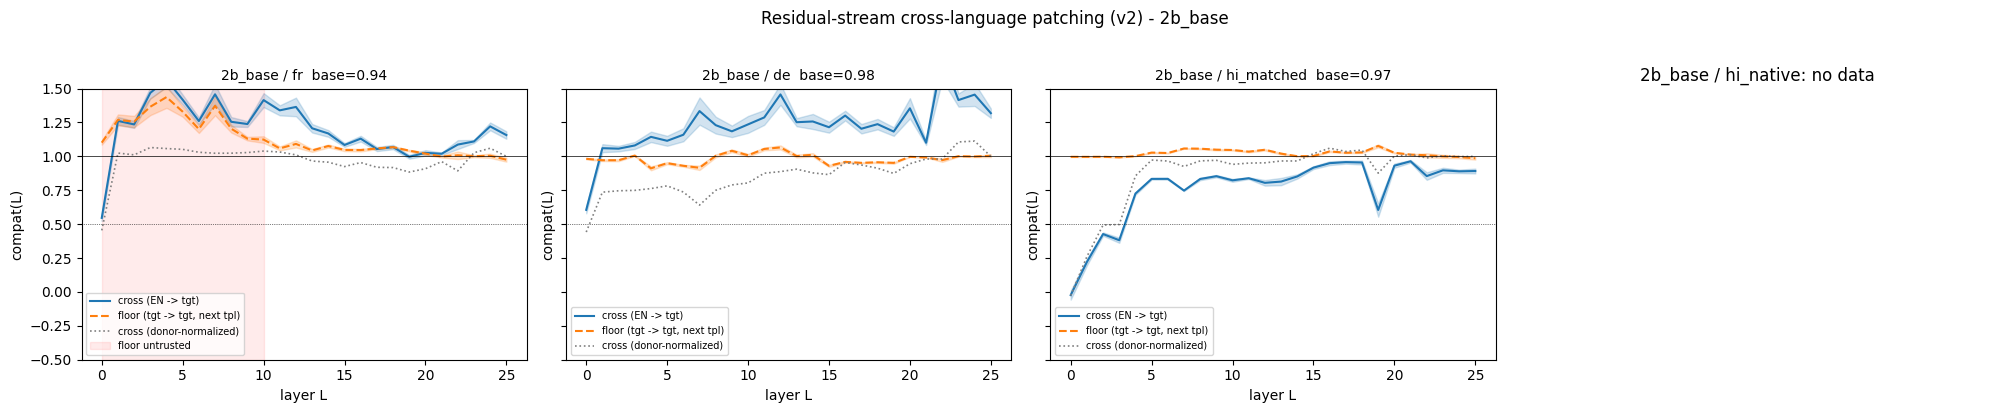

In [14]:
# RUN 1 — run the PREFLIGHT cell above first.
MODEL_KEY = "2b_base"
model, tok = load_model(MODEL_KEY)
_ = load_exp14_cache(MODEL_KEY)

ok, _c = self_test(model, tok)
assert ok, "SELF-TEST FAILED: hook is broken. STOP before running the sweep."

for lang in TARGET_LANGS:
    for seed in SEEDS:
        try:
            run_one(model, tok, MODEL_KEY, lang, seed)
        except LangUnavailable as e:
            print(f"[SKIP] {lang}: {e}")
            break

print()
print("=========== 2B SUMMARY ===========")
print_summary_table(model_keys=[MODEL_KEY])
print_compact_table(model_keys=[MODEL_KEY])
plot_model(MODEL_KEY)
free_model(model)

## RUN 2 — 9B base, 9B-it, 27B-it (only after inspecting RUN 1)

In [ ]:
# RUN 2 — only after RUN 1 looks sane. Per-(model, lang, seed) caching makes interruption / restart safe:
# finished cells reload from disk, so an exception on seed 2 of 27B costs nothing already done.
for MODEL_KEY in ["9b_base", "9b_it", "27b_it"]:
    model, tok = load_model(MODEL_KEY)
    _ = load_exp14_cache(MODEL_KEY)

    ok, _c = self_test(model, tok)
    if not ok:
        print(f"[WARNING] self-test failed on {MODEL_KEY}: skipping its sweep")
        free_model(model)
        continue

    for lang in TARGET_LANGS:
        for seed in SEEDS:
            try:
                run_one(model, tok, MODEL_KEY, lang, seed)
            except LangUnavailable as e:
                print(f"[SKIP] {lang}: {e}")
                break

    print()
    print(f"=========== {MODEL_KEY} SUMMARY ===========")
    print_summary_table(model_keys=[MODEL_KEY])
    plot_model(MODEL_KEY)
    free_model(model)

print()
print("=========== FULL CROSS-SCALE SUMMARY ===========")
print_compact_table()

[load] 9b_base  <-  /home/models/gemma-2-9b


Loading weights: 100%|██████████| 464/464 [00:07<00:00, 59.06it/s] 


[load] ready in 9.4s  n_layers=42  d_model=3584
[exp14 cache] exp14_results/9b_base.json not found (fine: prompts are built fresh)
[self-test] 6 EN prompts, mean clean logit-diff = +5.6250
  L=  0  patched=+5.6250  ablated=+2.4375  compat=+1.0000  ok=True
  L= 21  patched=+5.6250  ablated=+0.6667  compat=+1.0000  ok=True
  L= 41  patched=+5.6250  ablated=+0.0000  compat=+1.0000  ok=True
[self-test] all_ok = True
[baseline] 9b_base fr s0: target acc = 1.000  (gate 0.75)
[9b_base fr s0] 20/120  0.40 prompts/s  eta=252s
[9b_base fr s0] 40/120  0.40 prompts/s  eta=201s
[9b_base fr s0] 60/120  0.40 prompts/s  eta=150s
[9b_base fr s0] 80/120  0.41 prompts/s  eta=99s
[9b_base fr s0] 100/120  0.41 prompts/s  eta=49s
